In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
# from scipy.spatial.distance import jaccard, euclidean, cosine
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy
import squarify
try:
    import piplite
    await piplite.install(['ipywidgets'])
except ImportError:
    pass
import ipywidgets as widgets
import json

today = date.today()

**building 1kb regions**

In [3]:
chrm_lengths = [248956422, 242193529, 198295559, 190214555, 181538259, 170805979, 159345973, 145138636, 138394717, 133797422, 135086622, 133275309, 114364328, 107043718, 101991189, 90338345, 83257441, 80373285, 58617616, 64444167, 46709983, 50818468, 156040895, 57227415]
chrms = ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', 'X', 'Y']

In [12]:
# out_f = '/home/ctrader/region_similarity/data/rank_based/hg38_chromosome_lengths_CT20230327.tsv'
# np.savetxt(out_f, np.vstack((chrms, chrm_lengths)).T, fmt='%s', delimiter='\t')

In [24]:
chrom_len_path = '/home/ctrader/region_similarity/data/rank_based/hg38_chromosome_lengths_CT20230327.tsv'

# load lengths of chromosomes
chrm_lengths = []
chrms = []
f = open(chrom_len_path, 'r')
for line in f.readlines():
    line = line.strip().split('\t')
    chrms.append(line[0])
    chrm_lengths.append(int(line[1]))
f.close()

In [18]:
scale = 2000
bw = 1000

# create regions
bed_out = []
for c, l in zip(chrms, chrm_lengths):
    start = 0
    end = scale
    seqname = 'chr' + c
    while start < l:
        bed_out.append([seqname, start, end])
        start += bw
        end += bw
bed_out = np.array(bed_out)

In [49]:
out_path = '/home/ctrader/region_similarity/data/rank_based/hg38.1kb.regions.CT20230323.bed'

# save
np.savetxt(out_path, bed_out, fmt='%s', delimiter='\t')

**combining datasets and reducing precision**

In [88]:
def load_per(per_f):
    hdf5_f = h5py.File(per_f, 'r')
    percentile = hdf5_f['percentile'][:]
    factors = np.char.decode(hdf5_f['factors'][:])
    color = np.char.decode(hdf5_f['colors'][:])
    hdf5_f.close()
    return percentile, factors, color

In [89]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
DHS_per_f = datadir + 'regions_1kb_CT20230323.DHS.factornormNMF.sum_enrich_corank_percentile.hdf5'
epi_per_f = datadir + 'regions_1kb_CT20230323.epilogos.statesum_rank_percentile.hdf5'

# load region percentiles
DHS_per, DHS_factors, DHS_color = load_per(DHS_per_f)
epi_per, epi_factors, epi_color = load_per(epi_per_f)

In [90]:
percents = np.hstack((DHS_per, epi_per))
factor_order = np.append(DHS_factors, epi_factors)
metric_order = np.append(np.array(['DHSs'] * len(DHS_factors)),
                         np.array(['chromatin states'] *
                                  len(epi_factors)))
colors = np.append(DHS_color, epi_color)

In [91]:
percents.shape

(3088281, 34)

In [92]:
# datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
# out_f = datadir + 'regions_1kb_CT20230323.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.npy'
# print(out_f)
# np.save(out_f, percents.astype('float32'))

/home/ctrader/AG/NarrativeGenomics/region_narration/data/regions_1kb_CT20230323.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.npy


In [100]:
datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
per_f = datadir + 'regions_1kb_CT20230323.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.npy'

t = time.time()
percents = np.load(per_f)
time.time() - t

1.3436346054077148

In [96]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
regions_path = datadir + 'hg38.1kb.regions.CT20230323.sorted.bed'

f = open(regions_path, 'r')
regions_sep = []
for line in f.readlines():
    line = line.strip().split('\t')
    regions_sep.append(line)
f.close()
regions_sep = np.array(regions_sep)

In [97]:
regions_sep.shape

(3088281, 3)

In [98]:
# datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
# out_f = datadir + 'hg38.1kb.regions.CT20230323.sorted.bed.npy'

# print(out_f)
# np.save(out_f, regions_sep)

/home/ctrader/AG/NarrativeGenomics/region_narration/data/hg38.1kb.regions.CT20230323.sorted.bed.npy


In [99]:
datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
regions_path = datadir + 'hg38.1kb.regions.CT20230323.sorted.bed.npy'

t = time.time()
regions_sep = np.load(regions_path)
time.time() - t

0.8398733139038086

**Limiting Search Space**

In [109]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
rank_file = datadir + 'regions_2kb_CT20230327.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'

datadir = '/home/ctrader/region_similarity/data/rank_based/'
out_path = datadir + 'regions_2kb_CT20230327.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space.npz'

thresh = 0.95

In [110]:
hdf5_f = h5py.File(rank_file, 'r')
percents = hdf5_f['percentiles'][:]
regions = np.char.decode(hdf5_f['coordinates'][:])
hdf5_f.close()

In [111]:
inds_set = set()
for i in range(percents.shape[1]):
    inds = np.where(percents[:, i] >= thresh)[0]
    inds_set.update(inds)

In [112]:
top_inds = np.sort(list(inds_set))
top_percents = percents[top_inds]
top_regions = regions[top_inds]

# save
np.savez(out_path, percentiles=top_percents, coordinates=top_regions, original_inds=top_inds)

**Running a query**

In [92]:
# if str.isalpha(str(genomic_location)[0]):



# determine roi from hdf5 scale file
query_start_end = genomic_location.split(':')[1].split('-')
query_start = int(query_start_end[0])
query_end = int(query_start_end[1])

gz_tb = tabix.open(gz_file_path)
possible_coords = np.array(list(gz_tb.querys(genomic_location)))

start_dist = np.abs(possible_coords[:, 1].astype(int) - query_start)
end_dist = np.abs(possible_coords[:, 2].astype(int) - query_end)

query_region = possible_coords[np.argmin(start_dist + end_dist)]

roi = int(query_region[3])
# roi_coords = query_region[:3]


# else: # instead just load coordinates. Can accurately find region now
#     roi = int(genomic_location)

In [89]:
# load roi ranks
hdf5_f = h5py.File(query_path, 'r')
roi_percents = hdf5_f['percentiles'][roi]
roi_coords = np.char.decode(hdf5_f['coordinates'][roi])
hdf5_f.close()

In [105]:
# load search space ranks
search_space = np.load(search_space_path)
percents = search_space['percentiles']
regions_sep = search_space['coordinates']

In [163]:
def roiURL(roi, top_regions, detail_level, target_factors_str,
           link_type='dual'):
    today = date.today()
    roiurl_name = ('region_narration_simsearch_regions_roi_' + str(roi) +
                   '_detail_level_' + str(detail_level) + '_factors_' +
                   target_factors_str + '_scale_25kb_CT' +
                   today.strftime("%Y%m%d") + '.bed')
    bed_path_name = os.path.join('/home/ctrader/public_html/', roiurl_name)
    np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
    link_path1 = ('https://epilogos.altius.org:1234/?application=viewer&' +
                  'sampleSet=vC&mode=single&genome=hg38&model=18&complex' +
                  'ity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=800' +
                  '0&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%' +
                  '40resources.altius.org%2F~ctrader%2F' + roiurl_name)
    link_path2 = ('https://index.altius.org:1234/?application=viewer&mod' +
                  'e=pd&chrLeft=chr11&chrRight=chr11&start=47329800&stop' +
                  '=47356800&roiURL=https%3A%2F%2Fencode%3Acollabor8%40r' +
                  'esources.altius.org%2F~ctrader%2F' + roiurl_name)
    link_path_dual = ('https://index.altius.org:3000/?application=viewer' +
                      '&mode=cf&&roiURL=https%3A%2F%2Fencode%3Acollabor8' +
                      '%40resources.altius.org%2F~ctrader%2F' + roiurl_name)
    if link_type == 'dual':
        return link_path_dual
    else:
        return link_path1, link_path2


def load_per(per_f):
    hdf5_f = h5py.File(per_f, 'r')
    percentile = hdf5_f['percentile'][:]
    factors = np.char.decode(hdf5_f['factors'][:])
    color = np.char.decode(hdf5_f['colors'][:])
    hdf5_f.close()
    return percentile, factors, color


def top_region_sig(percents, top_regions):
    # mean and std of factor percentiles in all regions
    all_mean = np.mean(percents, axis=0)
    all_std = np.std(percents, axis=0)

    # mean of factor percentiles in most similar regions
    top_region_mean = np.mean(percents[top_regions[:, 1:]], axis=1)

    # Z score
    Z = (top_region_mean - all_mean) / (all_std / np.sqrt(top_regions.shape[1] - 1))

    # p-value (one sided)
    pval = stats.norm.sf(Z)

    return pval, Z


def simsearch(roi_percents, percents, roi, roi_coords, coords, included_factors, num_similar_regions):

    # factors the query region ranks highest in
    query_factor_order = np.argsort(-roi_percents)

    # factors to search over
    target_factors = query_factor_order[
        np.isin(query_factor_order, included_factors)
    ]

    # convolution
    roi_percents_targeted = roi_percents[target_factors]
    roi_conv_all = percents[:, target_factors] * roi_percents_targeted

    # fusion
    roi_sim_all = []
    for dl in range(1, len(included_factors) + 1):
        roi_sim = 1 - np.prod(1 - roi_conv_all[:, :dl], axis=1)
        roi_sim_all.append(roi_sim)
    roi_sim_all = np.array(roi_sim_all)

    # most similar regions
    top_regions = np.zeros(
        (len(included_factors), num_similar_regions + 1)
        , dtype=int
    )

    # top region genomic coordinates
    top_region_coords = np.ones(
        (len(included_factors), num_similar_regions + 1, 3),
        dtype=object
    ) * -1

    # add roi to top region lists
    top_regions[:, 0] = roi
    top_region_coords[:, 0] = roi_coords


    # adding similar regions
    sorted_sim_inds_all = np.argsort(-roi_sim_all, axis=1)

    # only add regions if no overlapping regions are already added
    for i in range(len(target_factors)):
        regions_added = 0
        for ind in sorted_sim_inds_all[i]:
            ind_coords = coords[ind]
            num_overlaps = np.count_nonzero(
                (top_region_coords[i][:, 0].astype(str) == ind_coords[0]) &
                (
                    (
                        (top_region_coords[i][:, 1].astype(int) > int(ind_coords[1])) &
                        (top_region_coords[i][:, 1].astype(int) < int(ind_coords[2]))
                    ) |
                    (
                        (top_region_coords[i][:, 2].astype(int) > int(ind_coords[1])) &
                        (top_region_coords[i][:, 2].astype(int) < int(ind_coords[2]))
                    ) |
                    (
                        (top_region_coords[i][:, 1].astype(int) == int(ind_coords[1])) &
                        (top_region_coords[i][:, 2].astype(int) == int(ind_coords[2]))
                    )
                )
            )
            if num_overlaps == 0:
                top_regions[i, regions_added + 1] = ind
                top_region_coords[i, regions_added + 1] = ind_coords
                regions_added += 1
            if regions_added == num_similar_regions:
                break

    # factor percentile significance
    pval, Z = top_region_sig(percents, top_regions)

    rows = (
        np.ones((len(target_factors), num_similar_regions), dtype=int) *
        np.arange(len(target_factors)).reshape(-1, 1)
    )

    return_sim = np.hstack((
        np.ones(len(target_factors)).reshape(-1, 1),
        roi_sim_all[rows, top_regions[:, 1:]]
    ))
    return_per = np.hstack((
        np.array([roi_percents.reshape(1, -1)] * len(target_factors)),
        percents[top_regions[:, 1:]]
    ))

    return (top_regions, top_region_coords, return_sim, return_per, 
            query_factor_order, target_factors, pval, Z)

In [225]:
t = time.time()
# factors the query region ranks highest in
query_factor_order = np.argsort(-roi_percents)

print('1', time.time() - t)

# factors to search over
target_factors = query_factor_order[
    np.isin(query_factor_order, included_factors)
]

print('2', time.time() - t)

# convolution
roi_percents_targeted = roi_percents[target_factors]

print('3.1', time.time() - t)

roi_conv_all = percents[:, target_factors] * roi_percents_targeted

print('3.2', time.time() - t)

# fusion
roi_sim_all = []
for dl in range(1, len(included_factors) + 1):
    roi_sim = 1 - np.prod(1 - roi_conv_all[:, :dl], axis=1)
    roi_sim_all.append(roi_sim)
roi_sim_all = np.array(roi_sim_all)

print('4', time.time() - t)

# most similar regions
top_regions = np.zeros(
    (len(included_factors), num_similar_regions + 1)
    , dtype=int
)

print('5', time.time() - t)

# top region genomic coordinates
top_region_coords = np.ones(
    (len(included_factors), num_similar_regions + 1, 3),
    dtype=object
) * -1

print('6', time.time() - t)

# add roi to top region lists
top_regions[:, 0] = roi
top_region_coords[:, 0] = roi_coords

print('7', time.time() - t)


# adding similar regions
sorted_sim_inds_all = np.argsort(-roi_sim_all, axis=1)

print('8', time.time() - t)

# only add regions if no overlapping regions are already added
for i in range(len(target_factors)):
    regions_added = 0
    for ind in sorted_sim_inds_all[i]:
        ind_coords = coords[ind]
        num_overlaps = np.count_nonzero(
            (top_region_coords[i][:, 0].astype(str) == ind_coords[0]) &
            (
                (
                    (top_region_coords[i][:, 1].astype(int) > int(ind_coords[1])) &
                    (top_region_coords[i][:, 1].astype(int) < int(ind_coords[2]))
                ) |
                (
                    (top_region_coords[i][:, 2].astype(int) > int(ind_coords[1])) &
                    (top_region_coords[i][:, 2].astype(int) < int(ind_coords[2]))
                ) |
                (
                    (top_region_coords[i][:, 1].astype(int) == int(ind_coords[1])) &
                    (top_region_coords[i][:, 2].astype(int) == int(ind_coords[2]))
                )
            )
        )
        if num_overlaps == 0:
            top_regions[i, regions_added + 1] = ind
            top_region_coords[i, regions_added + 1] = ind_coords
            regions_added += 1
        if regions_added == num_similar_regions:
            break
            
print('9', time.time() - t)

# factor percentile significance
pval, Z = top_region_sig(percents, top_regions)

print('10', time.time() - t)

rows = (
    np.ones((len(target_factors), num_similar_regions), dtype=int) *
    np.arange(len(target_factors)).reshape(-1, 1)
)

print('11', time.time() - t)

return_sim = np.hstack((
    np.ones(len(target_factors)).reshape(-1, 1),
    roi_sim_all[rows, top_regions[:, 1:]]
))

print('12', time.time() - t)

return_per = np.hstack((
    np.array([roi_percents.reshape(1, -1)] * len(target_factors)),
    percents[top_regions[:, 1:]]
))

print('13', time.time() - t)

# return (top_regions, top_region_coords, return_sim, return_per, 
#         query_factor_order, target_factors, pval, Z)

1 0.00034546852111816406
2 0.0009417533874511719
3.1 0.001293182373046875
3.2 0.003615856170654297
4 0.006788730621337891
5 0.007242918014526367
6 0.007622480392456055
7 0.008012056350708008
8 0.04473543167114258
9 0.7463278770446777
10 0.7533855438232422
11 0.7538974285125732
12 0.7542963027954102
13 0.7546892166137695


In [28]:
t = time.time()
all_mean = np.mean(percents, axis=0)
print(time.time() - t)
all_std = np.std(percents, axis=0)
print(time.time() - t)

# mean of factor percentiles in most similar regions
top_region_mean = np.mean(percents[top_regions[:, 1:]], axis=1)
print(time.time() - t)

# Z score
Z = (top_region_mean - all_mean) / (all_std / np.sqrt(top_regions.shape[1] - 1))
print(time.time() - t)

# p-value (one sided)
pval = stats.norm.sf(Z)
print(time.time() - t)

0.08216691017150879
0.30583858489990234
0.3067820072174072
0.3071603775024414
0.30848050117492676


In [29]:
percents.shape

(1067075, 34)

In [31]:
t = time.time()
all_std = np.std(percents[:], axis=0)
print(time.time() - t)

0.26922607421875


In [27]:
t = time.time()
roi_conv_all = percents[:100000, target_factors] * roi_percents_targeted
print(time.time() - t)

roi_sim_all = []
for dl in range(1, len(included_factors) + 1):
    roi_sim = 1 - np.prod(1 - roi_conv_all[:, :dl], axis=1)
    roi_sim_all.append(roi_sim)
roi_sim_all = np.array(roi_sim_all)
print(time.time() - t)

0.026697874069213867
0.04464101791381836


In [23]:
t = time.time()
x = np.argsort(-roi_sim_all[:, :100000], axis=1)
time.time() - t

0.1252899169921875

In [13]:
roi_sim_all.shape

(12, 1067075)

In [227]:
def load_roi(genomic_location, gz_file_path):
    global roi
    # determine roi from hdf5 scale file
    query_start_end = genomic_location.split(':')[1].split('-')
    query_start = int(query_start_end[0])
    query_end = int(query_start_end[1])

    gz_tb = tabix.open(gz_file_path)
    possible_coords = np.array(list(gz_tb.querys(genomic_location)))

    start_dist = np.abs(possible_coords[:, 1].astype(int) - query_start)
    end_dist = np.abs(possible_coords[:, 2].astype(int) - query_end)

    query_region = possible_coords[np.argmin(start_dist + end_dist)]

    roi = int(query_region[3])


def load_ranks(query_path, search_space_path):
    global roi_percents, percents, roi_coords, coords
    
    # load roi ranks
    hdf5_f = h5py.File(query_path, 'r')
    roi_percents = hdf5_f['percentiles'][roi]
    roi_coords = np.char.decode(hdf5_f['coordinates'][roi])
    hdf5_f.close()
    
    # load search space ranks
    search_space = np.load(search_space_path)
    percents = search_space['percentiles']#[:34000]
    coords = search_space['coordinates']#[:34000]


def setup_included_factors(included_factors_str, query_factor_thresh):
    global included_factors
    included_factors = np.int_(
        included_factors_str.strip('[').strip(']').split(',')
    )
    query_factors_above_thresh = np.where(roi_percents > query_factor_thresh)[0]
    included_factors = included_factors[
        np.isin(included_factors, query_factors_above_thresh)
    ]


def find_most_similar_region_indices(num_similar_regions):
    global top_regions, top_region_coords, top_regions_sim, top_regions_per, query_factor_order, target_factors, pval, Z
    (top_regions, top_region_coords, top_regions_sim,
     top_regions_per, query_factor_order,
     target_factors, pval,
     Z) = simsearch(roi_percents, percents, roi, roi_coords, coords, included_factors, num_similar_regions)


def setup_roiURLs(get_roiURL, target_factors):
    global roiURLs
    roiURLs = []
    for dl in range(1, len(included_factors) + 1):
        if get_roiURL == 'True':
            # roiURLs.append('roiURL not available')
            roiURLs.append(roiURL(roi, top_region_coords[dl-1],
                                  dl, '_'.join(target_factors.astype(str))))
        else:
            roiURLs.append('roiURL not available')


def reorder_by_query_region():
    global return_top_regions_per, return_pval, return_Z
    return_top_regions_per = top_regions_per[:, :, query_factor_order]
    return_pval = pval[:, query_factor_order]
    return_Z = Z[:, query_factor_order]


def generate_result_array(num_similar_regions):
    global return_arr_full
    return_arr_full = []
    for dl in range(len(included_factors)):
        # for the roi, return results as json array
        # each element is an object of scores for each metric
        return_arr = []
        for rank in range(num_similar_regions + 1):
            coord = top_region_coords[dl, rank]
            region_dict = {
                'rank': rank,
                'coordinates': coord[0] + ':' + coord[1] + '-' + coord[2],
                'region_ind': int(top_regions[dl, rank]),
                'score': float(top_regions_sim[dl, rank]),
                'percentiles': return_top_regions_per[dl, rank].tolist(),
            }
            if rank == 0:
                region_dict['region_ind'] = 'NA'
                region_dict['score'] = 'NA'
                region_dict['query_factor_order'] = query_factor_order.tolist()
                region_dict['target_factors'] = target_factors.tolist()
                region_dict['top_region_factor_Z_score'] = return_Z[dl].tolist()
                region_dict['top_region_factor_pval'] = return_pval[dl].tolist()
                region_dict['roiURL'] = roiURLs[dl]
                region_dict['detail_level'] = dl + 1
            return_arr.append(region_dict)

        return_arr_full.append(return_arr)

In [223]:
datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
query_path = datadir + 'regions_100kb_CT20230327.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'
gz_file_path = datadir + 'hg38.100kb.regions.CT20230327.sorted.rownum4.bed.gz'
search_space_path = datadir + 'regions_100kb_CT20230327.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space.npz'

genomic_location = 'chr4:173515000-173615000'
num_similar_regions = 20
included_factors_str = '[' + ','.join(np.arange(34).astype(str)) + ']'
query_factor_thresh=0.5
get_roiURL = 'False'

In [224]:
# load ROI
load_roi(genomic_location, gz_file_path)

# load region percentiles
load_ranks(query_path, search_space_path)

# factors the user cares about
setup_included_factors(included_factors_str, query_factor_thresh)

# find most similar region inds
find_most_similar_region_indices(num_similar_regions)

# dual track roiURL
setup_roiURLs(get_roiURL, target_factors)

# reorder based on query region
reorder_by_query_region()

# generate result array
generate_result_array(num_similar_regions)

json_return = json.dumps(return_arr_full)
# sys.stdout.write(json_return)

**How much should we limit search space?**

In [219]:
def simsearch(roi_percents, percents, roi, roi_coords, coords, included_factors, num_similar_regions):

    # factors the query region ranks highest in
    query_factor_order = np.argsort(-roi_percents)

    # factors to search over
    target_factors = query_factor_order[
        np.isin(query_factor_order, included_factors)
    ]

    # convolution
    roi_percents_targeted = roi_percents[target_factors]
    roi_conv_all = percents[:, target_factors] * roi_percents_targeted

    # fusion
    roi_sim_all = []
    for dl in range(1, len(included_factors) + 1):
        roi_sim = 1 - np.prod(1 - roi_conv_all[:, :dl], axis=1)
        roi_sim_all.append(roi_sim)
    roi_sim_all = np.array(roi_sim_all)

    # most similar regions
    top_regions = np.zeros(
        (len(included_factors), num_similar_regions + 1)
        , dtype=int
    )

    # top region genomic coordinates
    top_region_coords = np.ones(
        (len(included_factors), num_similar_regions + 1, 3),
        dtype=object
    ) * -1

    # add roi to top region lists
    top_regions[:, 0] = roi
    top_region_coords[:, 0] = roi_coords


    # adding similar regions
    sorted_sim_inds_all = np.argsort(-roi_sim_all, axis=1)

    # only add regions if no overlapping regions are already added
    for i in range(len(target_factors)):
        regions_added = 0
        for ind in sorted_sim_inds_all[i]:
            ind_coords = coords[ind]
            num_overlaps = np.count_nonzero(
                (top_region_coords[i][:, 0].astype(str) == ind_coords[0]) &
                (
                    (
                        (top_region_coords[i][:, 1].astype(int) > int(ind_coords[1])) &
                        (top_region_coords[i][:, 1].astype(int) < int(ind_coords[2]))
                    ) |
                    (
                        (top_region_coords[i][:, 2].astype(int) > int(ind_coords[1])) &
                        (top_region_coords[i][:, 2].astype(int) < int(ind_coords[2]))
                    ) |
                    (
                        (top_region_coords[i][:, 1].astype(int) == int(ind_coords[1])) &
                        (top_region_coords[i][:, 2].astype(int) == int(ind_coords[2]))
                    )
                )
            )
            if num_overlaps == 0:
                top_regions[i, regions_added + 1] = ind
                top_region_coords[i, regions_added + 1] = ind_coords
                regions_added += 1
            if regions_added == num_similar_regions:
                break

    # factor percentile significance
#     pval, Z = top_region_sig(percents, top_regions)

    rows = (
        np.ones((len(target_factors), num_similar_regions), dtype=int) *
        np.arange(len(target_factors)).reshape(-1, 1)
    )

    return_sim = np.hstack((
        np.ones(len(target_factors)).reshape(-1, 1),
        roi_sim_all[rows, top_regions[:, 1:]]
    ))
    return_per = np.hstack((
        np.array([roi_percents.reshape(1, -1)] * len(target_factors)),
        percents[top_regions[:, 1:]]
    ))

    return (top_regions, top_region_coords, return_sim, return_per)

def setup_included_factors(included_factors_str, query_factor_thresh, roi_percents):
#     global included_factors
    included_factors = np.int_(
        included_factors_str.strip('[').strip(']').split(',')
    )
    query_factors_above_thresh = np.where(roi_percents > query_factor_thresh)[0]
    included_factors = included_factors[
        np.isin(included_factors, query_factors_above_thresh)
    ]
    return included_factors

def load_roi(genomic_location, gz_file_path):
    # determine roi from hdf5 scale file
    query_start_end = genomic_location.split(':')[1].split('-')
    query_start = int(query_start_end[0])
    query_end = int(query_start_end[1])

    gz_tb = tabix.open(gz_file_path)
    possible_coords = np.array(list(gz_tb.querys(genomic_location)))

    start_dist = np.abs(possible_coords[:, 1].astype(int) - query_start)
    end_dist = np.abs(possible_coords[:, 2].astype(int) - query_end)

    query_region = possible_coords[np.argmin(start_dist + end_dist)]

    roi = int(query_region[3])
    return roi

Full (unlimited)

In [102]:
datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
query_path = datadir + 'regions_100kb_CT20230327.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'
gz_file_path = datadir + 'hg38.100kb.regions.CT20230327.sorted.rownum4.bed.gz'
search_space_path = datadir + 'regions_100kb_CT20230327.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space.npz'

genomic_location = 'chr6:73515000-73615000'
num_similar_regions = 20
included_factors_str = '[' + ','.join(np.arange(34).astype(str)) + ']'
query_factor_thresh=0.5
get_roiURL = 'False'

In [103]:
roi = load_roi(genomic_location, gz_file_path)
print(roi)

2334841


In [110]:
len(percents_full)

3088281

In [104]:
# load roi ranks
hdf5_f = h5py.File(query_path, 'r')
roi_percents = hdf5_f['percentiles'][roi]
roi_coords = np.char.decode(hdf5_f['coordinates'][roi])
hdf5_f.close()

# load ranks from ALL regions
hdf5_f = h5py.File(query_path, 'r')
percents_full = hdf5_f['percentiles'][:]
coords_full = np.char.decode(hdf5_f['coordinates'][:])
hdf5_f.close()

In [105]:
included_factors = setup_included_factors(included_factors_str, query_factor_thresh, roi_percents)

In [106]:
s_full = simsearch(roi_percents, 
                   percents_full, 
                   roi, 
                   roi_coords, 
                   coords_full, 
                   included_factors,
                   num_similar_regions)

In [107]:
s_full_per = s_full[-1]

In [108]:
s_full_simper = s_full_per[:, 1:, :]
print(np.max(s_full_simper, axis=2)[-1])
print(np.min(np.max(s_full_simper, axis=2)[-1]))

[0.990386   0.9679963  0.9643712  0.9327282  0.9778237  0.96001744
 0.9297873  0.9876544  0.95454603 0.9953188  0.90595424 0.98369116
 0.9543683  0.99531645 0.99995714 0.9365818  0.97871196 0.975172
 0.993982   0.85711485]
0.85711485


0.85711485

In [109]:
roi_percents

array([0.7801451 , 0.9346686 , 0.8092471 , 0.707238  , 0.6369303 ,
       0.8135896 , 0.6580981 , 0.44233403, 0.8025709 , 0.80014056,
       0.69242   , 0.8728349 , 0.49962988, 0.85856885, 0.5765327 ,
       0.94316316, 0.9667757 , 0.8040538 , 0.95567995, 0.59220505,
       0.2894587 , 0.6049628 , 0.95800614, 0.9924698 , 0.87347615,
       0.94071954, 0.39236006, 0.        , 0.        , 0.17496051,
       0.0575855 , 0.        , 0.        , 0.13187785], dtype=float32)

In [92]:
np.max(s_full_simper, axis=2).shape

(23, 20)

In [94]:
s_full_simper[-1, -1]

array([0.85329694, 0.767844  , 0.8244819 , 0.5362493 , 0.49752128,
       0.6259261 , 0.7606568 , 0.35380065, 0.7661664 , 0.8467148 ,
       0.70713794, 0.6754667 , 0.5905317 , 0.45365137, 0.47719607,
       0.85711485, 0.77725744, 0.55101943, 0.7373814 , 0.7648747 ,
       0.        , 0.        , 0.        , 0.        , 0.62636465,
       0.632913  , 0.49834067, 0.06537832, 0.        , 0.4472921 ,
       0.100661  , 0.17841204, 0.01233299, 0.53268385], dtype=float32)

Random sampling of regions

In [132]:
datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
query_path = datadir + 'regions_100kb_CT20230327.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'

# load ranks from ALL regions
hdf5_f = h5py.File(query_path, 'r')
percents_full = hdf5_f['percentiles'][:]
coords_full = np.char.decode(hdf5_f['coordinates'][:])
hdf5_f.close()

In [133]:
num_similar_regions = 20
included_factors_str = '[' + ','.join(np.arange(34).astype(str)) + ']'
query_factor_thresh=0.5

In [143]:
min_pers = []
i = 0
while len(min_pers) < 100:
    i += 1
    if i % 10 == 0:
        print(i)
        
    roi = random.randint(0, len(percents_full))

    # load roi ranks
    hdf5_f = h5py.File(query_path, 'r')
    roi_percents = hdf5_f['percentiles'][roi]
    roi_coords = np.char.decode(hdf5_f['coordinates'][roi])
    hdf5_f.close()
    
    included_factors = setup_included_factors(included_factors_str, query_factor_thresh, roi_percents)
    
    if len(included_factors) > 0:
        s_full = simsearch(roi_percents, 
                           percents_full, 
                           roi, 
                           roi_coords, 
                           coords_full, 
                           included_factors,
                           num_similar_regions)

        s_full_per = s_full[-1]
        s_full_simper = s_full_per[:, 1:, :]
        min_maxfper = np.min(np.max(s_full_simper, axis=2))

        min_pers.append(min_maxfper)

10
20
30
40
50
60
70
80
90
100


In [145]:
describe(min_pers)

DescribeResult(nobs=100, minmax=(0.80255926, 0.9891297), mean=0.92642695, variance=0.0013128492153353162, skewness=-1.0192427091896694, kurtosis=0.953994009873183)

Top 1000 regions from each factor

In [276]:
ranks_path = datadir + 'regions_100kb_CT20230327.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'
thresh = 1000


# load all ranks/coordinates
hdf5_f = h5py.File(ranks_path, 'r')
percents = hdf5_f['percentiles'][:]
regions = np.char.decode(hdf5_f['coordinates'][:])
hdf5_f.close()


# find top <thresh> regions for each factor and combine
top_inds = np.unique(np.argsort(-percents, axis=0)[:thresh])


# find corresponding ranks/coordinates
top_percents = percents[top_inds]
top_regions = regions[top_inds]

Comparing full to top 1000

In [30]:
datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
query_path = datadir + 'regions_100kb_CT20230327.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'

# load ranks from ALL regions
hdf5_f = h5py.File(query_path, 'r')
percents_full = hdf5_f['percentiles'][:]
coords_full = np.char.decode(hdf5_f['coordinates'][:])
hdf5_f.close()

In [31]:
thresh = 1000

# find top <thresh> regions for each factor and combine
top_inds = np.unique(np.argsort(-percents_full, axis=0)[:thresh])

# find corresponding ranks/coordinates
percents_1000 = percents_full[top_inds]
coords_1000 = coords_full[top_inds]
original_inds_1000 = top_inds

In [32]:
num_similar_regions = 20
included_factors_str = '[' + ','.join(np.arange(34).astype(str)) + ']'
query_factor_thresh=0.5

In [33]:
sim_ind_full = []
sims_ind_1000 = []
i = 0
while len(sim_ind_full) < 100:
    i += 1
    if i % 10 == 0:
        print(i)
        
    roi = random.randint(0, len(percents_full))

    # load roi ranks
    hdf5_f = h5py.File(query_path, 'r')
    roi_percents = hdf5_f['percentiles'][roi]
    roi_coords = np.char.decode(hdf5_f['coordinates'][roi])
    hdf5_f.close()
    
    included_factors = setup_included_factors(included_factors_str, query_factor_thresh, roi_percents)
    
    if len(included_factors) > 0:
        s_full = simsearch(roi_percents, 
                           percents_full, 
                           roi, 
                           roi_coords, 
                           coords_full, 
                           included_factors,
                           num_similar_regions)

        s_full_inds = s_full[0]
        sim_ind_full.append(s_full_inds)
        
        s_1000 = simsearch(roi_percents, 
                           percents_1000, 
                           roi, 
                           roi_coords, 
                           coords_1000, 
                           included_factors,
                           num_similar_regions)
        
        s_1000_inds = s_1000[0]
        # convert to the original inds
        s_1000_inds[:, 1:] = original_inds_1000[s_1000_inds[:, 1:]]
        sims_ind_1000.append(s_1000_inds)

10
20
30
40
50
60
70
80
90
100


In [44]:
percents_full[1280581]

array([0.7589248 , 0.7408074 , 0.6455231 , 0.7379914 , 0.5489289 ,
       0.6203799 , 0.70917344, 0.5037105 , 0.7090086 , 0.727898  ,
       0.42612776, 0.5192258 , 0.6000586 , 0.6214514 , 0.77987176,
       0.99727017, 0.9880956 , 0.9944415 , 0.90018857, 0.9089068 ,
       0.4950672 , 0.2464078 , 0.29913226, 0.27616432, 0.44241023,
       0.48958018, 0.27946803, 0.998315  , 0.9505558 , 0.26564193,
       0.        , 0.        , 0.        , 0.        ], dtype=float32)

In [46]:
percents_full[1266018]

array([0.73200595, 0.67509   , 0.63562024, 0.3029962 , 0.12431359,
       0.5178    , 0.20498317, 0.33124092, 0.57759565, 0.7370267 ,
       0.3011952 , 0.17779244, 0.11380397, 0.4375821 , 0.4526106 ,
       0.96763676, 0.6684212 , 0.60517734, 0.69385445, 0.77556604,
       0.28014785, 0.08144631, 0.        , 0.2421744 , 0.        ,
       0.05100868, 0.08937424, 0.9996378 , 0.9802525 , 0.38625944,
       0.09002398, 0.05236248, 0.        , 0.        ], dtype=float32)

In [45]:
percents_full[2221021]

array([0.24161175, 0.76197326, 0.67034286, 0.5515728 , 0.27293506,
       0.72259223, 0.70275605, 0.49005252, 0.3279111 , 0.6722232 ,
       0.39041087, 0.36189914, 0.46098962, 0.44565606, 0.43308192,
       0.89858925, 0.6879479 , 0.63779986, 0.512342  , 0.6866242 ,
       0.        , 0.        , 0.12370214, 0.8592553 , 0.        ,
       0.        , 0.        , 0.9995475 , 0.98513466, 0.40699568,
       0.26414338, 0.40951827, 0.        , 0.        ], dtype=float32)

In [63]:
np.where(original_inds_1000 == 2221021)

(array([], dtype=int64),)

In [53]:
np.where(np.argsort(-percents_full[:, -7]) == 1266018)

(array([802]),)

In [77]:
sims_ind_1000[0][0]

array([ 784665, 1286663,  650882, 1286534,  650982, 1237815, 1285009,
       1265296, 1265876, 1286411, 1889928, 1280431,  897543, 1264986,
       1284864, 1265580, 1286020, 1265179,  650760, 1266018, 1280581])

In [78]:
sim_ind_full[0][0]

array([ 784665, 1286663,  650882, 1286534,  650982, 1237815, 1285009,
       1265296, 1265876, 1286411, 1889928, 1280431,  897543, 1264986,
       1284864, 1265580, 1286020, 1265179,  650760, 1266018, 2221021])

In [56]:
print(sims_ind_1000[0])

print(sim_ind_full[0])

[[ 784665 1286663  650882 1286534  650982 1237815 1285009 1265296 1265876
  1286411 1889928 1280431  897543 1264986 1284864 1265580 1286020 1265179
   650760 1266018 1280581]
 [ 784665 1211698  724468 2392342 2137752 1286663  650882 1286534  650982
  1237815 1285009 1265296 1265876 1286411 1889928 1280431  897543 1264986
  1284864 1265580 1286020]
 [ 784665 1211698 2137752  724484 1251798 1281473 1250341 1282055 1280400
  1252000 1281312 1251462 1265226 1286074 1825318 1251311  834025 1250747
  2874641 2368109 1265953]]
[[ 784665 1286663  650882 1286534  650982 1237815 1285009 1265296 1265876
  1286411 1889928 1280431  897543 1264986 1284864 1265580 1286020 1265179
   650760 1266018 2221021]
 [ 784665 1256167  555797 2777542 1419268 2635016  552116 1379126 1328506
   603736  783971 2777442 2019773  189268 1482091 1471562  601622 1252682
   405754  558227 1085164]
 [ 784665 1256166 2777542  555797 2635016 1328506  552116 1379124 1085164
  1252677  558227 1419265  339092 2186330 2180402 

In [60]:
np.argmax(percents_full[784665])

27

In [61]:
percents_full[2221021][27]

0.9995475

In [62]:
percents_full[1280581][27]

0.998315

In [71]:
np.argsort(-percents_full[:, 27])[:1000]

array([1286663,  650882,  650883,  650881,  650884, 1286664, 1286665,
       1286662,  650885, 1286666,  650886,  650887,  650888,  650899,
        650889, 1286667,  650900, 1286661,  650890,  650901,  650898,
        650880,  650902,  650891,  650903, 1286660, 1286668,  650892,
       1286657, 1286659, 1286656, 1286658,  650904,  650893, 1286655,
        650894,  650897,  650895,  650905,  650896, 1286654,  650879,
       1286653,  650906,  650878, 1286652, 1286669,  650907,  650871,
        650870,  650877,  650869,  650872,  650908, 1286651, 1286670,
        650868,  650876,  650909,  650867,  650873, 1286650, 1286671,
        650875,  650874,  650866,  650910, 1286672, 1286649, 1286674,
       1286673,  650911,  650865, 1286675,  650916, 1286676, 1286648,
        650917,  650912,  650864,  650939, 1286677,  650918,  650915,
        650913,  650914,  650863, 1286647,  650938,  650919, 1286607,
       1286606, 1286608, 1286678, 1286609,  650940,  650862, 1286605,
        650937, 1286

In [72]:
original_inds_1000[np.argsort(-percents_1000[:, 27])[:1000]]

array([1286663,  650882,  650883,  650881,  650884, 1286664, 1286665,
       1286662,  650885, 1286666,  650886,  650887,  650888,  650899,
        650889, 1286667,  650900, 1286661,  650890,  650901,  650898,
        650880,  650902,  650891,  650903, 1286660, 1286668,  650892,
       1286657, 1286659, 1286656, 1286658,  650904,  650893, 1286655,
        650894,  650897,  650895,  650905,  650896, 1286654,  650879,
       1286653,  650906,  650878, 1286652, 1286669,  650907,  650871,
        650870,  650877,  650869,  650872,  650908, 1286651, 1286670,
        650868,  650876,  650909,  650867,  650873, 1286650, 1286671,
        650875,  650874,  650866,  650910, 1286672, 1286649, 1286674,
       1286673,  650911,  650865, 1286675,  650916, 1286676, 1286648,
        650917,  650912,  650864,  650939, 1286677,  650918,  650915,
        650913,  650914,  650863, 1286647,  650938,  650919, 1286607,
       1286606, 1286608, 1286678, 1286609,  650940,  650862, 1286605,
        650937, 1286

In [81]:
roi = 784665
roi_percents = percents_full[roi]
roi_coords = coords_full[roi]
included_factors = setup_included_factors(included_factors_str, query_factor_thresh, roi_percents)

In [99]:
# factors the query region ranks highest in
query_factor_order = np.argsort(-roi_percents)

# factors to search over
target_factors = query_factor_order[
    np.isin(query_factor_order, included_factors)
]

# convolution
roi_percents_targeted = roi_percents[target_factors]
roi_conv_all = percents_1000[:, target_factors] * roi_percents_targeted

# fusion
roi_sim_all = []
for dl in range(1, len(included_factors) + 1):
    roi_sim = 1 - np.prod(1 - roi_conv_all[:, :dl], axis=1)
    roi_sim_all.append(roi_sim)
roi_sim_all = np.array(roi_sim_all)

# most similar regions
top_regions = np.zeros(
    (len(included_factors), num_similar_regions + 1)
    , dtype=int
)

# top region genomic coordinates
top_region_coords_1000 = np.ones(
    (len(included_factors), num_similar_regions + 1, 3),
    dtype=object
) * -1

# add roi to top region lists
top_regions[:, 0] = roi
top_region_coords_1000[:, 0] = roi_coords


# adding similar regions
sorted_sim_inds_all = np.argsort(-roi_sim_all, axis=1)

# only add regions if no overlapping regions are already added
for i in range(len(target_factors))[:1]:
    regions_added = 0
    c = 0
    for ind in sorted_sim_inds_all[i]:
        c += 1
        ind_coords_1000 = coords_1000[ind]
        num_overlaps = np.count_nonzero(
            (top_region_coords_1000[i][:, 0].astype(str) == ind_coords_1000[0]) &
            (
                (
                    (top_region_coords_1000[i][:, 1].astype(int) > int(ind_coords_1000[1])) &
                    (top_region_coords_1000[i][:, 1].astype(int) < int(ind_coords_1000[2]))
                ) |
                (
                    (top_region_coords_1000[i][:, 2].astype(int) > int(ind_coords_1000[1])) &
                    (top_region_coords_1000[i][:, 2].astype(int) < int(ind_coords_1000[2]))
                ) |
                (
                    (top_region_coords_1000[i][:, 1].astype(int) == int(ind_coords_1000[1])) &
                    (top_region_coords_1000[i][:, 2].astype(int) == int(ind_coords_1000[2]))
                )
            )
        )
        if num_overlaps == 0:
            top_regions[i, regions_added + 1] = ind
            top_region_coords_1000[i, regions_added + 1] = ind_coords_1000
            regions_added += 1
        if regions_added == num_similar_regions:
            break

In [102]:
top_region_coords_full[0]

array([['chr14', '19182000', '19282000'],
       ['chr19', '58173000', '58273000'],
       ['chr12', '133040000', '133140000'],
       ['chr19', '58044000', '58144000'],
       ['chr12', '133140000', '133240000'],
       ['chr19', '9325000', '9425000'],
       ['chr19', '56519000', '56619000'],
       ['chr19', '36806000', '36906000'],
       ['chr19', '37386000', '37486000'],
       ['chr19', '57921000', '58021000'],
       ['chr4', '356000', '456000'],
       ['chr19', '51941000', '52041000'],
       ['chr15', '25016000', '25116000'],
       ['chr19', '36496000', '36596000'],
       ['chr19', '56374000', '56474000'],
       ['chr19', '37090000', '37190000'],
       ['chr19', '57530000', '57630000'],
       ['chr19', '36689000', '36789000'],
       ['chr12', '132918000', '133018000'],
       ['chr19', '37528000', '37628000'],
       ['chr5', '141234000', '141334000']], dtype=object)

In [105]:
coords_full[784665]

array(['chr14', '19182000', '19282000'], dtype='<U9')

In [ ]:
chr14:19182000-19282000

In [111]:
np.argsort(-percents_full[:, 27])[:1000]

array([1286663,  650882,  650883,  650881,  650884, 1286664, 1286665,
       1286662,  650885, 1286666,  650886,  650887,  650888,  650899,
        650889, 1286667,  650900, 1286661,  650890,  650901,  650898,
        650880,  650902,  650891,  650903, 1286660, 1286668,  650892,
       1286657, 1286659, 1286656, 1286658,  650904,  650893, 1286655,
        650894,  650897,  650895,  650905,  650896, 1286654,  650879,
       1286653,  650906,  650878, 1286652, 1286669,  650907,  650871,
        650870,  650877,  650869,  650872,  650908, 1286651, 1286670,
        650868,  650876,  650909,  650867,  650873, 1286650, 1286671,
        650875,  650874,  650866,  650910, 1286672, 1286649, 1286674,
       1286673,  650911,  650865, 1286675,  650916, 1286676, 1286648,
        650917,  650912,  650864,  650939, 1286677,  650918,  650915,
        650913,  650914,  650863, 1286647,  650938,  650919, 1286607,
       1286606, 1286608, 1286678, 1286609,  650940,  650862, 1286605,
        650937, 1286

In [113]:
percents_full[1280581, 27]

0.998315

In [98]:
top_regions[0]

array([ 784665, 1286663,  650882, 1286534,  650982, 1237815, 1285009,
       1265296, 1265876, 1286411, 1889928, 1280431,  897543, 1264986,
       1284864, 1265580, 1286020, 1265179,  650760, 1266018, 2221021])

In [100]:
original_inds_1000[top_regions[0][1:]]

array([1286663,  650882, 1286534,  650982, 1237815, 1285009, 1265296,
       1265876, 1286411, 1889928, 1280431,  897543, 1264986, 1284864,
       1265580, 1286020, 1265179,  650760, 1266018, 1280581])

In [95]:
c

1172

In [97]:
c

1003

In [114]:
percents_full.shape

(3088281, 34)

Top 1000 regions with no overlaps

In [216]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
ranks_path = datadir + 'regions_100kb_CT20230327.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'
thresh = 1000

t = time.time()

# # load all ranks/coordinates
# hdf5_f = h5py.File(ranks_path, 'r')
# percents = hdf5_f['percentiles'][:]
# regions = np.char.decode(hdf5_f['coordinates'][:])
# hdf5_f.close()





# # find top <thresh> regions for each factor and combine
# top_inds = np.unique(np.argsort(-percents, axis=0)[:thresh])

overall_top_inds = []
for factor in range(percents.shape[1]):
    factor_top_inds = []
    factor_top_regions = (-1 * np.ones((thresh, 3), dtype=int)).astype(str)

    factor_sorted_inds = np.argsort(-percents[:, factor])
    factor_sorted_regions = regions[factor_sorted_inds]

    regions_added = 0
    for ind, coords in zip(factor_sorted_inds, factor_sorted_regions):
        num_overlaps = np.count_nonzero(
            (factor_top_regions[:, 0].astype(str) == coords[0]) &
            (
                (
                    (factor_top_regions[:, 1].astype(int) > int(coords[1])) &
                    (factor_top_regions[:, 1].astype(int) < int(coords[2]))
                ) |
                (
                    (factor_top_regions[:, 2].astype(int) > int(coords[1])) &
                    (factor_top_regions[:, 2].astype(int) < int(coords[2]))
                ) |
                (
                    (factor_top_regions[:, 1].astype(int) == int(coords[1])) &
                    (factor_top_regions[:, 2].astype(int) == int(coords[2]))
                )
            )
        )
        if num_overlaps == 0:
            factor_top_inds.append(ind)
            factor_top_regions[regions_added] = coords
            regions_added += 1
        if len(factor_top_inds) == thresh:
            break
    overall_top_inds.extend(factor_top_inds)
    print(time.time() - t)
top_inds = np.unique(overall_top_inds)

# find corresponding ranks/coordinates
top_percents = percents[top_inds]
top_regions = regions[top_inds]

73.4931697845459
146.11372542381287
223.43626260757446
297.281555891037


KeyboardInterrupt: 

**Comparing top 1000 (no overlaps) to full**

In [138]:
def simsearch(roi_percents, percents, roi, roi_coords, coords, included_factors, num_similar_regions):

    # factors the query region ranks highest in
    query_factor_order = np.argsort(-roi_percents)

    # factors to search over
    target_factors = query_factor_order[
        np.isin(query_factor_order, included_factors)
    ]

    # convolution
    roi_percents_targeted = roi_percents[target_factors]
    roi_conv_all = percents[:, target_factors] * roi_percents_targeted

    # fusion
    roi_sim_all = []
    for dl in range(1, len(included_factors) + 1):
        roi_sim = 1 - np.prod(1 - roi_conv_all[:, :dl], axis=1)
        roi_sim_all.append(roi_sim)
    roi_sim_all = np.array(roi_sim_all)

    # most similar regions
    top_regions = np.zeros(
        (len(included_factors), num_similar_regions + 1)
        , dtype=int
    )

    # top region genomic coordinates
    top_region_coords = np.ones(
        (len(included_factors), num_similar_regions + 1, 3),
        dtype=object
    ) * -1

    # add roi to top region lists
    top_regions[:, 0] = roi
    top_region_coords[:, 0] = roi_coords


    # adding similar regions
    sorted_sim_inds_all = np.argsort(-roi_sim_all, axis=1)

    # only add regions if no overlapping regions are already added
    for i in range(len(target_factors)):
        regions_added = 0
        for ind in sorted_sim_inds_all[i]:
            ind_coords = coords[ind]
            num_overlaps = np.count_nonzero(
                (top_region_coords[i][:, 0].astype(str) == ind_coords[0]) &
                (
                    (
                        (top_region_coords[i][:, 1].astype(int) > int(ind_coords[1])) &
                        (top_region_coords[i][:, 1].astype(int) < int(ind_coords[2]))
                    ) |
                    (
                        (top_region_coords[i][:, 2].astype(int) > int(ind_coords[1])) &
                        (top_region_coords[i][:, 2].astype(int) < int(ind_coords[2]))
                    ) |
                    (
                        (top_region_coords[i][:, 1].astype(int) == int(ind_coords[1])) &
                        (top_region_coords[i][:, 2].astype(int) == int(ind_coords[2]))
                    )
                )
            )
            if num_overlaps == 0:
                top_regions[i, regions_added + 1] = ind
                top_region_coords[i, regions_added + 1] = ind_coords
                regions_added += 1
            if regions_added == num_similar_regions:
                break

    # factor percentile significance
#     pval, Z = top_region_sig(percents, top_regions)

    rows = (
        np.ones((len(target_factors), num_similar_regions), dtype=int) *
        np.arange(len(target_factors)).reshape(-1, 1)
    )

    return_sim = np.hstack((
        np.ones(len(target_factors)).reshape(-1, 1),
        roi_sim_all[rows, top_regions[:, 1:]]
    ))
    return_per = np.hstack((
        np.array([roi_percents.reshape(1, -1)] * len(target_factors)),
        percents[top_regions[:, 1:]]
    ))

    return (top_regions, top_region_coords, return_sim, return_per)

def setup_included_factors(included_factors_str, query_factor_thresh, roi_percents):
#     global included_factors
    included_factors = np.int_(
        included_factors_str.strip('[').strip(']').split(',')
    )
    query_factors_above_thresh = np.where(roi_percents > query_factor_thresh)[0]
    included_factors = included_factors[
        np.isin(included_factors, query_factors_above_thresh)
    ]
    return included_factors

def load_roi(genomic_location, gz_file_path):
    # determine roi from hdf5 scale file
    query_start_end = genomic_location.split(':')[1].split('-')
    query_start = int(query_start_end[0])
    query_end = int(query_start_end[1])

    gz_tb = tabix.open(gz_file_path)
    possible_coords = np.array(list(gz_tb.querys(genomic_location)))

    start_dist = np.abs(possible_coords[:, 1].astype(int) - query_start)
    end_dist = np.abs(possible_coords[:, 2].astype(int) - query_end)

    query_region = possible_coords[np.argmin(start_dist + end_dist)]

    roi = int(query_region[3])
    return roi

def roiURL(roi, top_regions, detail_level, method, scale,
           link_type='dual'):
    today = date.today()
    roiurl_name = ('region_narration_simsearch_regions_roi_' + str(roi) +
                   '_detail_level_' + str(detail_level) + '_' + method + 
                   '_scale_' + scale + 'kb_CT' +
                   today.strftime("%Y%m%d") + '.bed')
    bed_path_name = os.path.join('/home/ctrader/public_html/', roiurl_name)
    np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
    link_path1 = ('https://epilogos.altius.org:1234/?application=viewer&' +
                  'sampleSet=vC&mode=single&genome=hg38&model=18&complex' +
                  'ity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=800' +
                  '0&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%' +
                  '40resources.altius.org%2F~ctrader%2F' + roiurl_name)
    link_path2 = ('https://index.altius.org:1234/?application=viewer&mod' +
                  'e=pd&chrLeft=chr11&chrRight=chr11&start=47329800&stop' +
                  '=47356800&roiURL=https%3A%2F%2Fencode%3Acollabor8%40r' +
                  'esources.altius.org%2F~ctrader%2F' + roiurl_name)
    link_path_dual = ('https://index.altius.org:3000/?application=viewer' +
                      '&mode=cf&&roiURL=https%3A%2F%2Fencode%3Acollabor8' +
                      '%40resources.altius.org%2F~ctrader%2F' + roiurl_name)
    if link_type == 'dual':
        return link_path_dual
    else:
        return link_path1, link_path2
    
def simsearch_overlap(roi_percents, percents, roi, roi_coords, coords, included_factors, num_similar_regions):

    # factors the query region ranks highest in
    query_factor_order = np.argsort(-roi_percents)

    # factors to search over
    target_factors = query_factor_order[
        np.isin(query_factor_order, included_factors)
    ]

    # convolution
    roi_percents_targeted = roi_percents[target_factors]
    roi_conv_all = percents[:, target_factors] * roi_percents_targeted

    # fusion
    roi_sim_all = []
    for dl in range(1, len(included_factors) + 1):
        roi_sim = 1 - np.prod(1 - roi_conv_all[:, :dl], axis=1)
        roi_sim_all.append(roi_sim)
    roi_sim_all = np.array(roi_sim_all)

    # most similar regions
    top_regions = np.zeros(
        (len(included_factors), num_similar_regions + 1)
        , dtype=int
    )

    # top region genomic coordinates
    top_region_coords = np.ones(
        (len(included_factors), num_similar_regions + 1, 3),
        dtype=object
    ) * -1

    # add roi to top region lists
    top_regions[:, 0] = roi
    top_region_coords[:, 0] = roi_coords


    # adding similar regions
    sorted_sim_inds_all = np.argsort(-roi_sim_all, axis=1)

    # only add regions if no overlapping regions are already added
    for i in range(len(target_factors)):
        regions_added = 0
        for ind in sorted_sim_inds_all[i]:
            ind_coords = coords[ind]
#             num_overlaps = np.count_nonzero(
#                 (top_region_coords[i][:, 0].astype(str) == ind_coords[0]) &
#                 (
#                     (
#                         (top_region_coords[i][:, 1].astype(int) > int(ind_coords[1])) &
#                         (top_region_coords[i][:, 1].astype(int) < int(ind_coords[2]))
#                     ) |
#                     (
#                         (top_region_coords[i][:, 2].astype(int) > int(ind_coords[1])) &
#                         (top_region_coords[i][:, 2].astype(int) < int(ind_coords[2]))
#                     ) |
#                     (
#                         (top_region_coords[i][:, 1].astype(int) == int(ind_coords[1])) &
#                         (top_region_coords[i][:, 2].astype(int) == int(ind_coords[2]))
#                     )
#                 )
#             )
            num_overlaps = 0
            if num_overlaps == 0:
                top_regions[i, regions_added + 1] = ind
                top_region_coords[i, regions_added + 1] = ind_coords
                regions_added += 1
            if regions_added == num_similar_regions:
                break

    # factor percentile significance
#     pval, Z = top_region_sig(percents, top_regions)

    rows = (
        np.ones((len(target_factors), num_similar_regions), dtype=int) *
        np.arange(len(target_factors)).reshape(-1, 1)
    )

    return_sim = np.hstack((
        np.ones(len(target_factors)).reshape(-1, 1),
        roi_sim_all[rows, top_regions[:, 1:]]
    ))
    return_per = np.hstack((
        np.array([roi_percents.reshape(1, -1)] * len(target_factors)),
        percents[top_regions[:, 1:]]
    ))

    return (top_regions, top_region_coords, return_sim, return_per)


In [139]:
scale = '25'
genomic_location = 'chrX:48778015-48802844'
num_similar_regions = 20
included_factors_str = '[' + ','.join(np.arange(34).astype(str)) +']'
query_factor_thresh = 0.5

In [140]:
datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
query_path = datadir + 'regions_' + scale + 'kb_CT20230330.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'

# load ranks from ALL regions
hdf5_f = h5py.File(query_path, 'r')
percents_full = hdf5_f['percentiles'][:]
coords_full = np.char.decode(hdf5_f['coordinates'][:])
hdf5_f.close()

In [141]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
sub_path = datadir + 'regions_' + scale + 'kb_CT20230403.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.npz'

percents_sub = np.load(sub_path)['percentiles']
coords_sub = np.load(sub_path)['coordinates']

In [142]:
datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
gz_file_path = datadir + 'hg38.' + scale + 'kb.regions.CT20230330.sorted.rownum4.bed.gz'

roi = load_roi(genomic_location, gz_file_path)

In [151]:
hdf5_f = h5py.File(query_path, 'r')
roi_percents = hdf5_f['percentiles'][roi]
roi_coords = np.char.decode(hdf5_f['coordinates'][roi])
hdf5_f.close()

included_factors = setup_included_factors(included_factors_str, query_factor_thresh, roi_percents)

s_full = simsearch(roi_percents, 
                   percents_full, 
                   roi, 
                   roi_coords, 
                   coords_full, 
                   included_factors,
                   num_similar_regions)

s_sub = simsearch(roi_percents, 
                  percents_sub, 
                  roi, 
                  roi_coords, 
                  coords_sub, 
                  included_factors,
                  num_similar_regions)

roiurls_full = []
roiurls_sub = []
for dl in range(included_factors.shape[0]):
    roiurls_full.append(roiURL(roi, s_full[1][dl], dl, 'full', scale))
    roiurls_sub.append(roiURL(roi, s_sub[1][dl], dl, 'top_1000', scale))

In [152]:
overlaps_all = []
for dl in range(included_factors.shape[0]):
    full_regions = s_full[1][dl][1:]
    overlaps = 0
    for sub_region in s_sub[1][dl][1:]:
        num_overlaps = np.count_nonzero(
            (full_regions[:, 0].astype(str) == sub_region[0]) &
            (
                (
                    (full_regions[:, 1].astype(int) > int(sub_region[1])) &
                    (full_regions[:, 1].astype(int) < int(sub_region[2]))
                ) |
                (
                    (full_regions[:, 2].astype(int) > int(sub_region[1])) &
                    (full_regions[:, 2].astype(int) < int(sub_region[2]))
                ) |
                (
                    (full_regions[:, 1].astype(int) == int(sub_region[1])) &
                    (full_regions[:, 2].astype(int) == int(sub_region[2]))
                )
            )
        )
        if num_overlaps > 0:
            overlaps += 1
    overlaps_all.append(overlaps)

In [153]:
num_overlaps

0

Text(0.5, 1.0, 'Top 1000 (No Overlap) vs Full Method Sim Serach Results\nGATA1, chrX:48778015-48802844, 25kb')

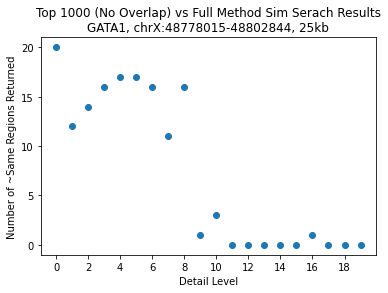

In [154]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(np.arange(len(overlaps_all)), overlaps_all)

plt.yticks([0, 5, 10, 15, 20])
plt.xticks(np.arange(0, included_factors.shape[0], 2))

plt.xlabel('Detail Level')
plt.ylabel('Number of ~Same Regions Returned')

plt.title('Top 1000 (No Overlap) vs Full Method Sim Serach Results\nGATA1, ' + genomic_location + ', ' + scale + 'kb')

In [146]:
roiurls_sub[1]

'https://index.altius.org:3000/?application=viewer&mode=cf&&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fregion_narration_simsearch_regions_roi_2923790_detail_level_1_top_1000_scale_25kb_CT20230403.bed'